# Random Forests

Once you understand decision trees, it becomes much easier to understand random forests. A random forest is a meta-estimator that trains many decision trees. It is called a random forest, because it uses a random subset of samples and features. By combining their predictions, averaging for regression or majority vote for classification, the random forest improves predictive accuracy and reduces overfitting compared to a single decision tree.

Note that each tree in the forest is trained on a random subset of the samples ([bootstrapping](https://en.wikipedia.org/wiki/Bootstrapping_(statistics))). By default, however, each tree still has access to all features when fitting to its subset of the data. The additional randomness comes from the fact that at each split, the tree does not consider all features but instead evaluates only a random subset of them.

The modern form of Random Forests was introduced by [Leo Breiman](https://scholar.google.com/citations?user=mXSv_1UAAAAJ&hl=en) in 2001 in his landmark paper [Random Forests](https://link.springer.com/article/10.1023/a:1010933404324). It was published in the journal [Machine Learning](https://link.springer.com/journal/10994/aims-and-scope). It combined previous ideas such as the [CART](https://www.taylorfrancis.com/books/mono/10.1201/9781315139470/classification-regression-trees-leo-breiman-jerome-friedman-olshen-charles-stone) algorithm we described previously and [Bagging Predictors](https://link.springer.com/article/10.1007/BF00058655), again a paper by Breiman published in 1996.

Random Forests were the dominant algorithms for tabular prediction tasks in the early years of Kaggle, before 2014-2015. They provided strong performance with minimal tuning and were widely used by top competitors.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1. A Random Forest from Decision Trees

Let's fit 9 decision trees, each trained on a different subset of the dataset. Together, these trees form a small random forest. Note that we will use all the features, since we only have two.

In [2]:
# DUMMY DATA GENERATION
# DO NOT MODIFY
np.random.seed(2) # fixed seed so that everyone gets the same data
n = 200
X = np.random.rand(n, 2) * 2
y = np.zeros(n, dtype='int')
y[(X[:, 0] > 1) & (X[:, 1] > 1)] = 1

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

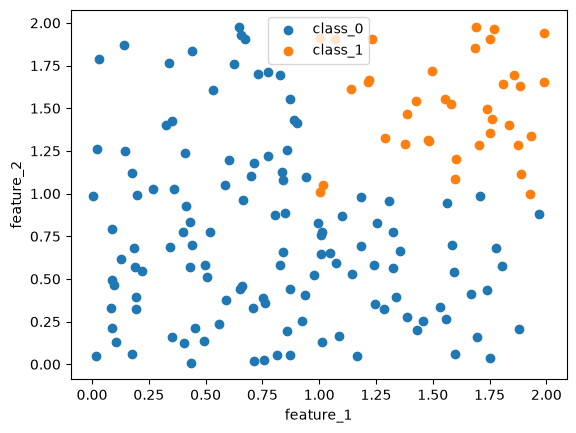

In [4]:
plt.figure(dpi=100)
plt.scatter(X_train[y_train==0][:, 0], X_train[y_train==0][:, 1], label='class_0')
plt.scatter(X_train[y_train==1][:, 0], X_train[y_train==1][:, 1], label='class_1')
plt.xlabel('feature_1')
plt.ylabel('feature_2')
plt.legend()

we can create a simple function to sample the dataset:

In [5]:
def sample_subset(X, y, ratio):
    '''
    Sampling with replacement
    This is how sampling is described in Bagging Predictors, L. Breiman, 1996
    '''
    n_samples = int(len(X)*ratio)
    idx = np.random.choice(len(X), size=n_samples, replace=True)
    return X[idx], y[idx]

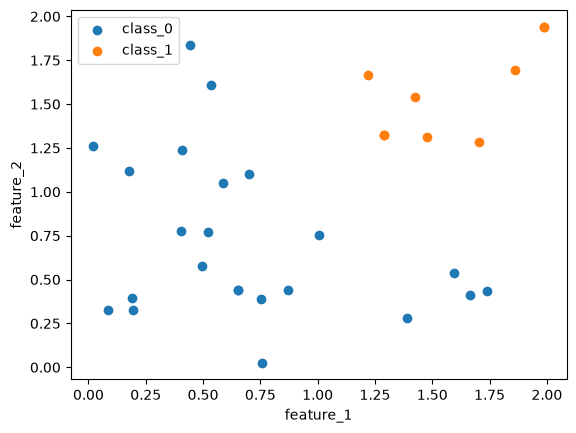

In [6]:
# run this cell multiple times
X_sub, y_sub = sample_subset(X_train, y_train, 0.2)

plt.figure(dpi=100)
plt.scatter(X_sub[y_sub==0][:, 0], X_sub[y_sub==0][:, 1], label='class_0')
plt.scatter(X_sub[y_sub==1][:, 0], X_sub[y_sub==1][:, 1], label='class_1')
plt.xlabel('feature_1')
plt.ylabel('feature_2')
plt.legend()

Now we can construct our random forest: we loop `n_estimators` times, draw a random bootstrap sample of the dataset, and train a decision tree on each sample.

In [7]:
from sklearn.tree import DecisionTreeClassifier
n_estimators = 9
random_forest = []
for i in range(n_estimators):
    X_sub, y_sub = sample_subset(X_train, y_train, 0.3)
    dt = DecisionTreeClassifier(random_state=0, max_depth=2, max_features=2) # max_features=2 we use all the features
    dt.fit(X_sub, y_sub)
    random_forest.append(dt)

In [8]:
random_forest

[DecisionTreeClassifier(max_depth=2, max_features=2, random_state=0),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=0),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=0),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=0),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=0),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=0),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=0),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=0),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=0)]

we can visualize the forest, and verify each tree has different `feature <= th` values

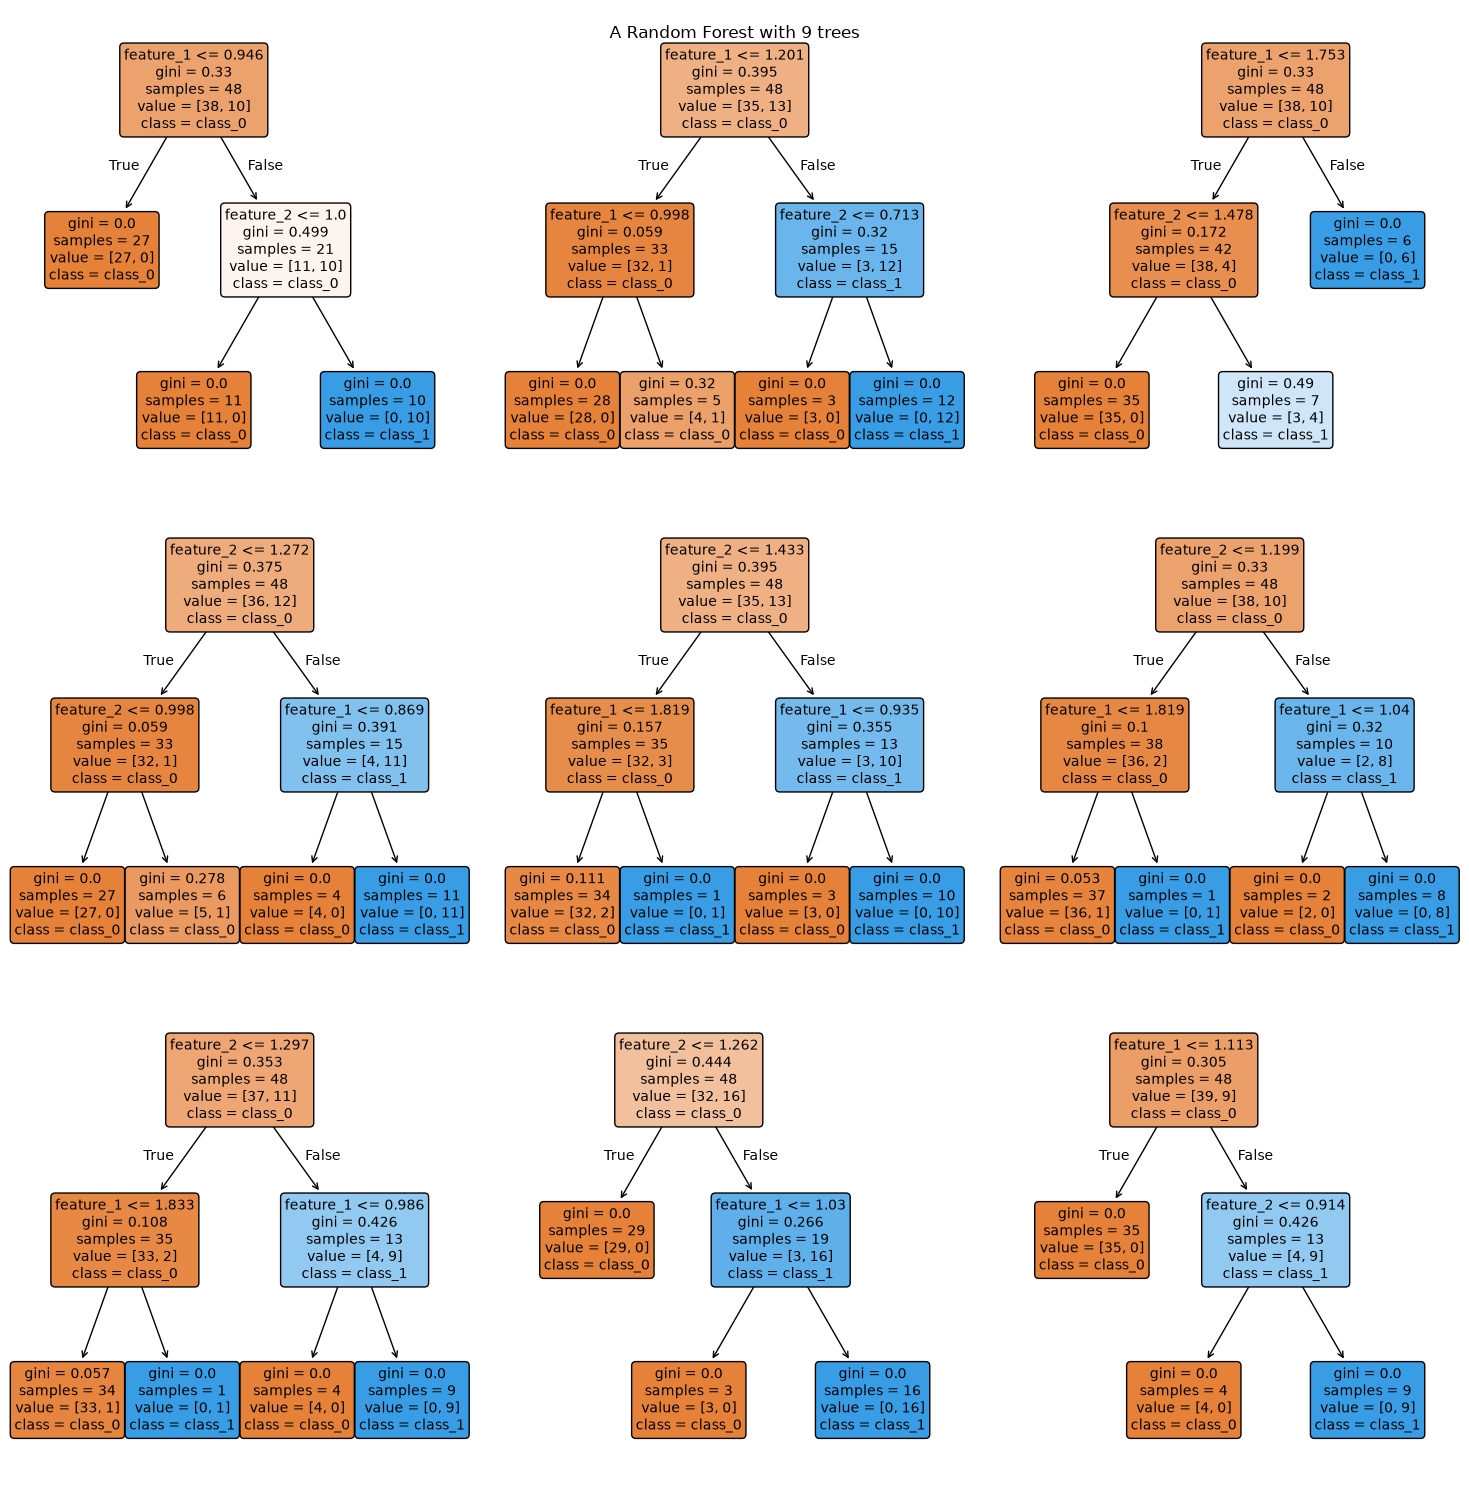

In [9]:
from sklearn.tree import plot_tree

n_estimators = len(random_forest)
rows, cols = 3, 3

fig, axes = plt.subplots(rows, cols, figsize=(15, 15), dpi=100)

axes = axes.flatten()  # make indexing easier

for i, (tree, ax) in enumerate(zip(random_forest, axes)):
    ax.set_title(f"Tree {i+1}")
    plot_tree(
        tree,
        feature_names=['feature_1', 'feature_2'],
        class_names=['class_0', 'class_1'],
        filled=True,
        rounded=True,
        fontsize=10,
        ax=ax
    )

# If you have only 5 trees, hide the last empty subplot
for j in range(i+1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
fig.suptitle(f'A Random Forest with {n_estimators} trees')
plt.show()

To understand how a random forest makes a final prediction, let's look at the predictions of each individual tree. We take one test sample, pass it through all trees, and collect their outputs.

In [10]:
# Each tree makes a prediction on the first test data point
feature_1, feature_2 = X_test[0]
preds = []
for tree_id, dt in enumerate(random_forest):
    pred = dt.predict([[feature_1, feature_2]])
    preds.append(pred[0])
    print(f"Tree {tree_id} predicts: {pred[0]}")

Tree 0 predicts: 1
Tree 1 predicts: 1
Tree 2 predicts: 0
Tree 3 predicts: 0
Tree 4 predicts: 0
Tree 5 predicts: 0
Tree 6 predicts: 0
Tree 7 predicts: 0
Tree 8 predicts: 1


In [11]:
# we can calculate the majority vote
majority_vote = int(sum(preds) / len(preds) > 0.5)
majority_vote

0

We looked at the first prediction, there might be full agreement between trees or not. Next, let's explicitly search for a test sample on which the trees do not all agree, so we can see how the random forest combines conflicting predictions:

In [12]:
for i, (feature_1, feature_2) in enumerate(X_test):
    preds = []
    for tree_id, dt in enumerate(random_forest):
        pred = dt.predict([[feature_1, feature_2]])
        preds.append(pred[0])

    if sum(preds) / len(preds) == 0:
        continue # all trees agree it is a 0
    elif sum(preds) / len(preds) == 1:
        continue # all trees agree it is a 1
    else:
        # means they do not agree
        disagreement_id = i
        break

In [13]:
# Let's check the disagreement
feature_1, feature_2 = X_test[disagreement_id]
preds = []
for tree_id, dt in enumerate(random_forest):
    pred = dt.predict([[feature_1, feature_2]])
    preds.append(pred[0])
    print(f"Tree {tree_id} predicts: {pred[0]}")

Tree 0 predicts: 1
Tree 1 predicts: 1
Tree 2 predicts: 0
Tree 3 predicts: 0
Tree 4 predicts: 0
Tree 5 predicts: 0
Tree 6 predicts: 0
Tree 7 predicts: 0
Tree 8 predicts: 1


In [14]:
majority_vote = int(sum(preds) / len(preds) > 0.5)
majority_vote

0

In [15]:
# check if the prediction is correct
y_test[disagreement_id] == majority_vote

np.False_

and finally let's repeat this process for all the test points and calculate the test accuracy:

In [16]:
y_pred = []
for i, (feature_1, feature_2) in enumerate(X_test): # loop each test datapoint
    preds = []
    for tree_id, dt in enumerate(random_forest): # loop each tree on a given datapoint
        pred = dt.predict([[feature_1, feature_2]])
        preds.append(pred[0])

    majority_vote = int(sum(preds) / len(preds) > 0.5)

    y_pred.append(majority_vote)

In [17]:
from sklearn.metrics import accuracy_score
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)

Accuracy: 0.9


## 2. RandomForestClassifier

Let's replicate what we have done above, with `RandomForestClassifier`

In [18]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=0, n_estimators=9, max_features=2, max_depth=2)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",9
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, d

this is how you can reach the trees

In [19]:
rf.estimators_

[DecisionTreeClassifier(max_depth=2, max_features=2, random_state=209652396),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=398764591),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=924231285),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=1478610112),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=441365315),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=1537364731),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=192771779),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=1491434855),
 DecisionTreeClassifier(max_depth=2, max_features=2, random_state=1819583497)]

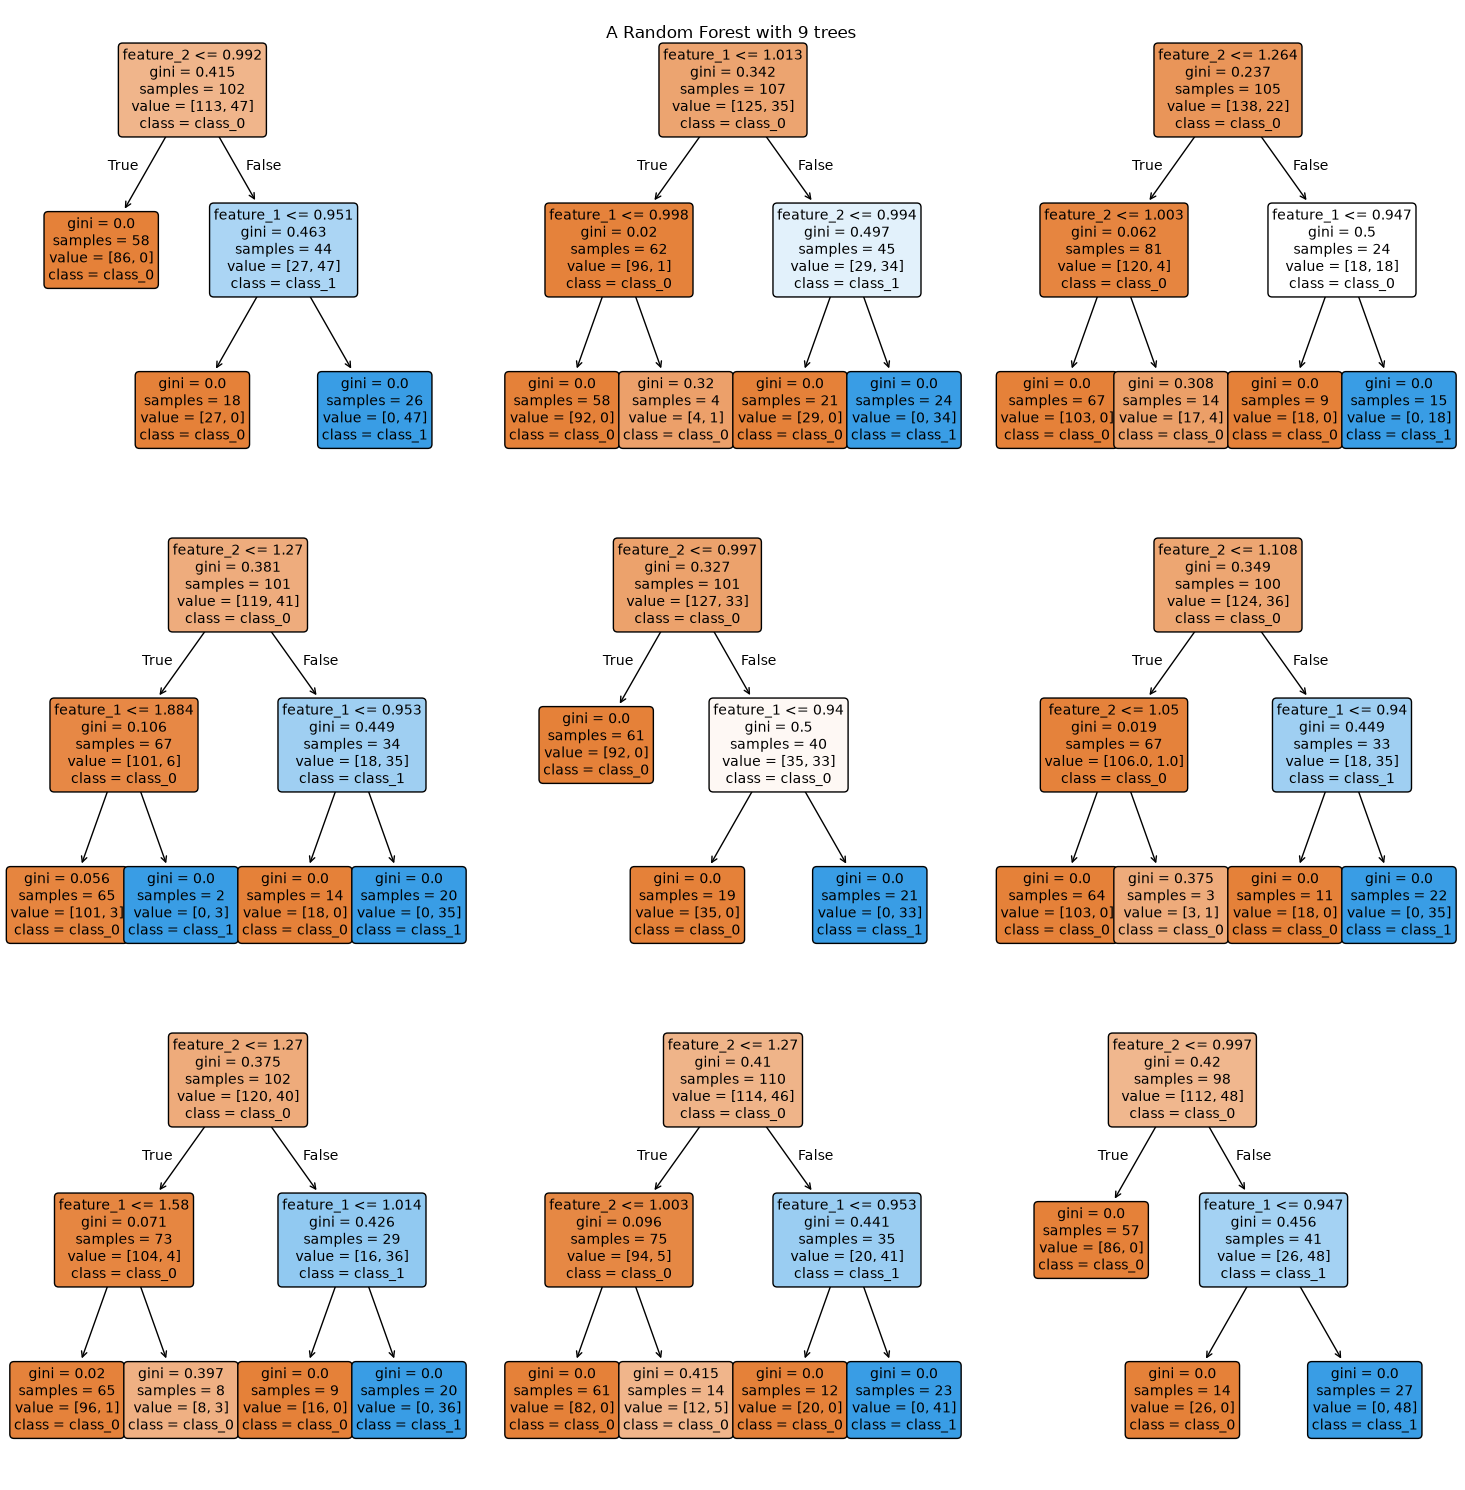

In [20]:
n_estimators = len(rf.estimators_)
rows, cols = 3, 3

fig, axes = plt.subplots(rows, cols, figsize=(15, 15), dpi=100)

axes = axes.flatten()  # make indexing easier

for i, (tree, ax) in enumerate(zip(rf.estimators_, axes)):
    ax.set_title(f"Tree {i+1}")
    plot_tree(
        tree,
        feature_names=['feature_1', 'feature_2'],
        class_names=['class_0', 'class_1'],
        filled=True,
        rounded=True,
        fontsize=10,
        ax=ax
    )

# If you have only 5 trees, hide the last empty subplot
for j in range(i+1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
fig.suptitle(f'A Random Forest with {n_estimators} trees')
plt.show()

In [21]:
y_pred = rf.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)

Accuracy: 1.0


You may notice that the accuracy differs between our earlier implementation and this one. Why could that happen?

One of the most common attributes of a random forest is `feature_importances_`. This tells us how important each feature is for making predictions across the entire forest.

A single decision tree computes feature importance by looking at how much each split reduces impurity. You have already seen that every split chooses a feature and threshold that maximally reduces Gini impurity. For that tree, the importance of a feature is the total impurity reduction contributed by all splits that use that feature. Deep splits count less than early splits, because they affect fewer samples.

A random forest simply averages these importance values across all trees. Features that consistently lead to large impurity reductions (especially near the top of trees) receive high importance scores. Features that are rarely chosen, or whose splits do not reduce impurity much, get small scores.

This makes `feature_importances_` a useful, model-specific measure of how strongly each feature contributes to the forest’s decisions.

---

Given the symmetry in our dataset, we would anticipate both features to have similar importance. Let's verify this by examining the feature importance values from our random forest.

In [22]:
rf.feature_importances_

array([0.50174306, 0.49825694])

## 3. Hyperparameters

At this point, you can read and understand almost all the hyperparameters in the documentation. Notice how RandomForests and DecisionTrees share many parameters:

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

You already learned `n_estimators` which determines the number of trees.

In [23]:
rf = RandomForestClassifier(random_state=0, n_estimators=1000)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [24]:
len(rf.estimators_)

1000

Random forests do not evaluate all features at every split. Instead, they randomly select a subset of features and search for the best split within that subset. This subset size is controlled by `max_features`. The default value is `"sqrt"`, meaning the algorithm will consider √p features at each split, where p is the total number of features. For example, if `X` has 16 features, each split will be evaluated using only 4 randomly chosen features.


In [25]:
rf = RandomForestClassifier(random_state=0, max_features='sqrt')
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

you can provide integers or fractions as well. See the details in the documentation.

`n_jobs` controls how many CPU cores the random forest is allowed to use when training or predicting.

A random forest trains many trees independently, so these trees can be built *in parallel*. That is exactly what `n_jobs` does:

* `n_jobs=None`
  This is the default. It means “use 1 core”.

* `n_jobs=1`
  Explicitly use a single CPU core.

* `n_jobs=-1`
  Use all available CPU cores on your machine. This is the typical setting when you want faster training.

* `n_jobs=k`
  Use exactly *k* cores (for example `n_jobs=4` uses 4 cores).

Both `.fit()` and `.predict()` will run faster when more cores are used because each tree is handled by a different core.

Therefore `n_jobs=-1` can be especially helpful when hyperparameter tuning with large datasets. Let's create a dataset with 1 million datapoints.

In [26]:
# DUMMY DATA GENERATION
# DO NOT MODIFY
np.random.seed(0) # fixed seed so that everyone gets the same data
n = 1000000
X = np.random.rand(n, 2) * 2
y = np.zeros(n, dtype='int')
y[(X[:, 0] > 1) & (X[:, 1] > 1)] = 1

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [27]:
%%time
# one CPU core
rf = RandomForestClassifier(random_state=0, n_jobs=1) # n_jobs = 1
rf.fit(X_train, y_train)

CPU times: user 16 s, sys: 732 ms, total: 16.8 s
Wall time: 16.8 s


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [28]:
%%time
# all CPU cores: compare the wall time with the cell above
rf = RandomForestClassifier(random_state=0, n_jobs=-1) # n_jobs = -1
rf.fit(X_train, y_train)

CPU times: user 22.1 s, sys: 1.2 s, total: 23.3 s
Wall time: 2.88 s


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total 

<mark>YOUR TURN</mark>

We will not cover every hyperparameter in detail. At this point, you know enough to read the documentation and learn the rest through experimentation.

1. Open the [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) documentation.
2. Read through all the hyperparameters, their descriptions, and the values they can take.
3. Choose a few hyperparameters we did not discuss and experiment with them, just like we did above, to see how they affect the forest.


In [29]:
# YOUR CODE HERE